In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ast
import plotly.graph_objects as go
from pathlib import Path

In [ ]:
root = Path.cwd()
if not (root / "data").exists():
    root = root.parent

train_path = root / "data/raw/data/train/A-1.parquet"
test_path = root / "data/raw/data/test/A-1.parquet"

train = pd.read_parquet(train_path)
test = pd.read_parquet(test_path)

print("Train shape:", train.shape)
print("Test shape:", test.shape)

display(train.head())


Train shape: (2880, 26)
Test shape: (8640, 26)


,timestep,value,cmd_0,cmd_1,cmd_2,cmd_3,cmd_4,cmd_5,cmd_6,cmd_7,...,cmd_14,cmd_15,cmd_16,cmd_17,cmd_18,cmd_19,cmd_20,cmd_21,cmd_22,cmd_23
0,0,0.999,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,0.999,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2,0.999,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,3,0.999,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,0.999,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


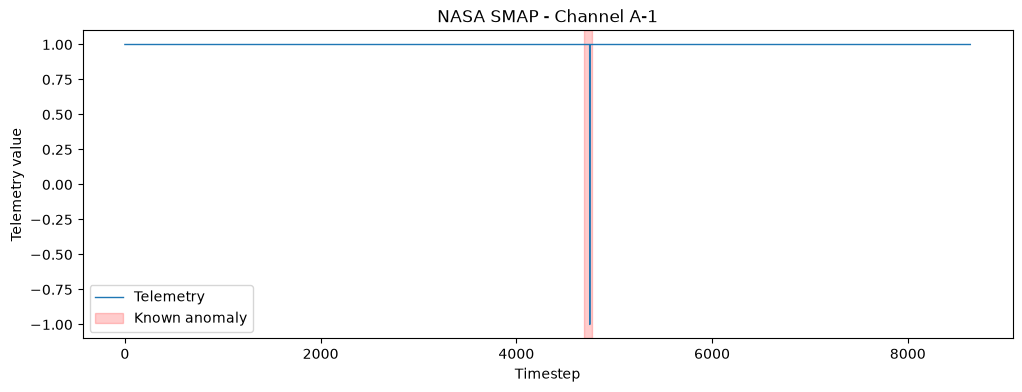

In [ ]:

labels = pd.read_csv(
    root / "data/raw/labeled_anomalies.csv"
)

anomaly_text = labels.loc[
    labels["chan_id"] == "A-1",
    "anomaly_sequences"
].iloc[0]

anomaly_ranges = ast.literal_eval(anomaly_text)

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    test["timestep"],
    test["value"],
    label="Telemetry",
    linewidth=1
)

for start, end in anomaly_ranges:
    ax.axvspan(
        start, end,
        color="red",
        alpha=0.2,
        label="Known anomaly"
    )

ax.set_title("NASA SMAP - Channel A-1")
ax.set_xlabel("Timestep")
ax.set_ylabel("Telemetry value")
ax.legend()
plt.show()


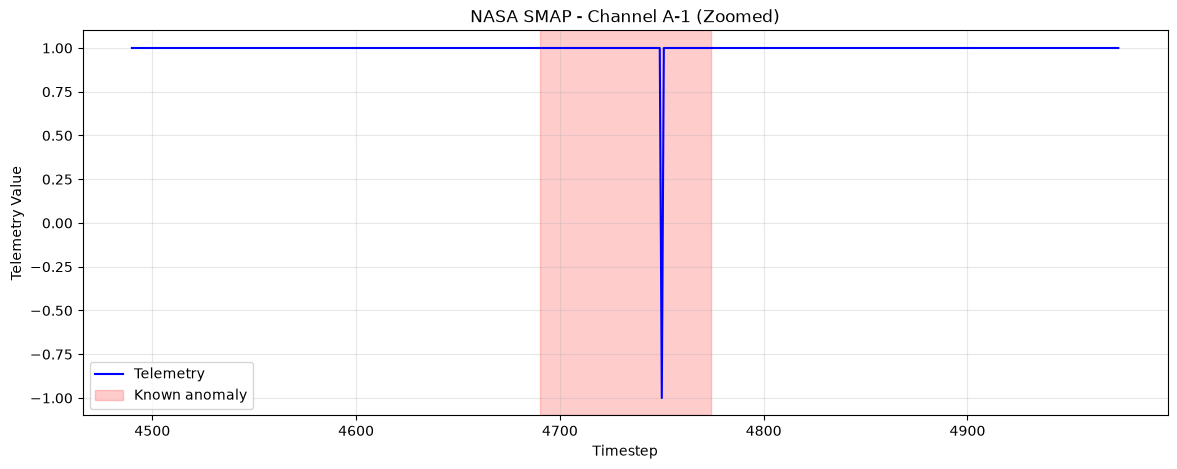

In [4]:
# Zoom into the first labeled anomaly
start, end = anomaly_ranges[0]

# Show 200 timesteps before and after
padding = 200

left = max(0, start - padding)
right = end + padding

# Select only the relevant telemetry
zoom_data = test[
    test["timestep"].between(left, right)
]

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    zoom_data["timestep"],
    zoom_data["value"],
    color="blue",
    linewidth=1.5,
    label="Telemetry"
)

ax.axvspan(
    start,
    end,
    color="red",
    alpha=0.2,
    label="Known anomaly"
)

ax.set_title("NASA SMAP - Channel A-1 (Zoomed)")
ax.set_xlabel("Timestep")
ax.set_ylabel("Telemetry Value")
ax.grid(True, alpha=0.3)
ax.legend()

plt.show()


In [ ]:

# Locate the lowest telemetry reading
dip_position = np.argmin(test["value"].to_numpy())

# Display measurements surrounding the drop
near_dip = test.iloc[
    max(0, dip_position - 10):dip_position + 11
]

display(near_dip[["timestep", "value"]])

# Count measurements inside the labeled interval
start, end = anomaly_ranges[0]

anomaly_data = test[
    test["timestep"].between(start, end)
]

print("Labeled interval length:", len(anomaly_data))
print("Minimum telemetry value:", anomaly_data["value"].min())
print("Readings below zero:", (anomaly_data["value"] < 0).sum())


,timestep,value
4740,4740,1.0
4741,4741,1.0
4742,4742,1.0
4743,4743,1.0
4744,4744,1.0
4745,4745,1.0
4746,4746,1.0
4747,4747,1.0
4748,4748,1.0
4749,4749,1.0


Labeled interval length: 85
Minimum telemetry value: -1.0
Readings below zero: 1


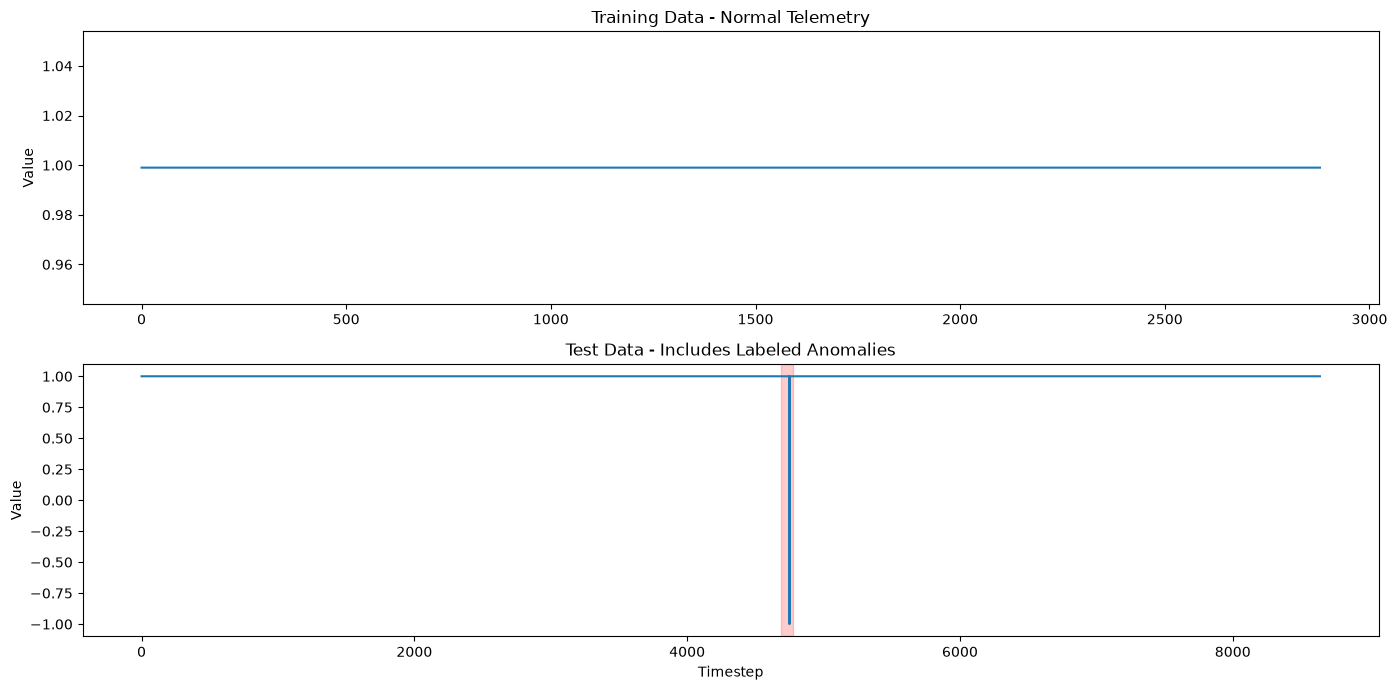

Training statistics:


count    2.880000e+03
mean     9.990000e-01
std      1.110416e-16
min      9.990000e-01
25%      9.990000e-01
50%      9.990000e-01
75%      9.990000e-01
max      9.990000e-01
Name: value, dtype: float64

Testing statistics:


count    8640.000000
mean        0.999769
std         0.021517
min        -1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max         1.000000
Name: value, dtype: float64

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7))

# Training data
axes[0].plot(train["timestep"], train["value"])
axes[0].set_title("Training Data - Normal Telemetry")
axes[0].set_ylabel("Value")

# Test data
axes[1].plot(test["timestep"], test["value"])

for start, end in anomaly_ranges:
    axes[1].axvspan(start, end, color="red", alpha=0.2)

axes[1].set_title("Test Data - Includes Labeled Anomalies")
axes[1].set_xlabel("Timestep")
axes[1].set_ylabel("Value")

plt.tight_layout()
plt.show()

print("Training statistics:")
display(train["value"].describe())

print("Testing statistics:")
display(test["value"].describe())


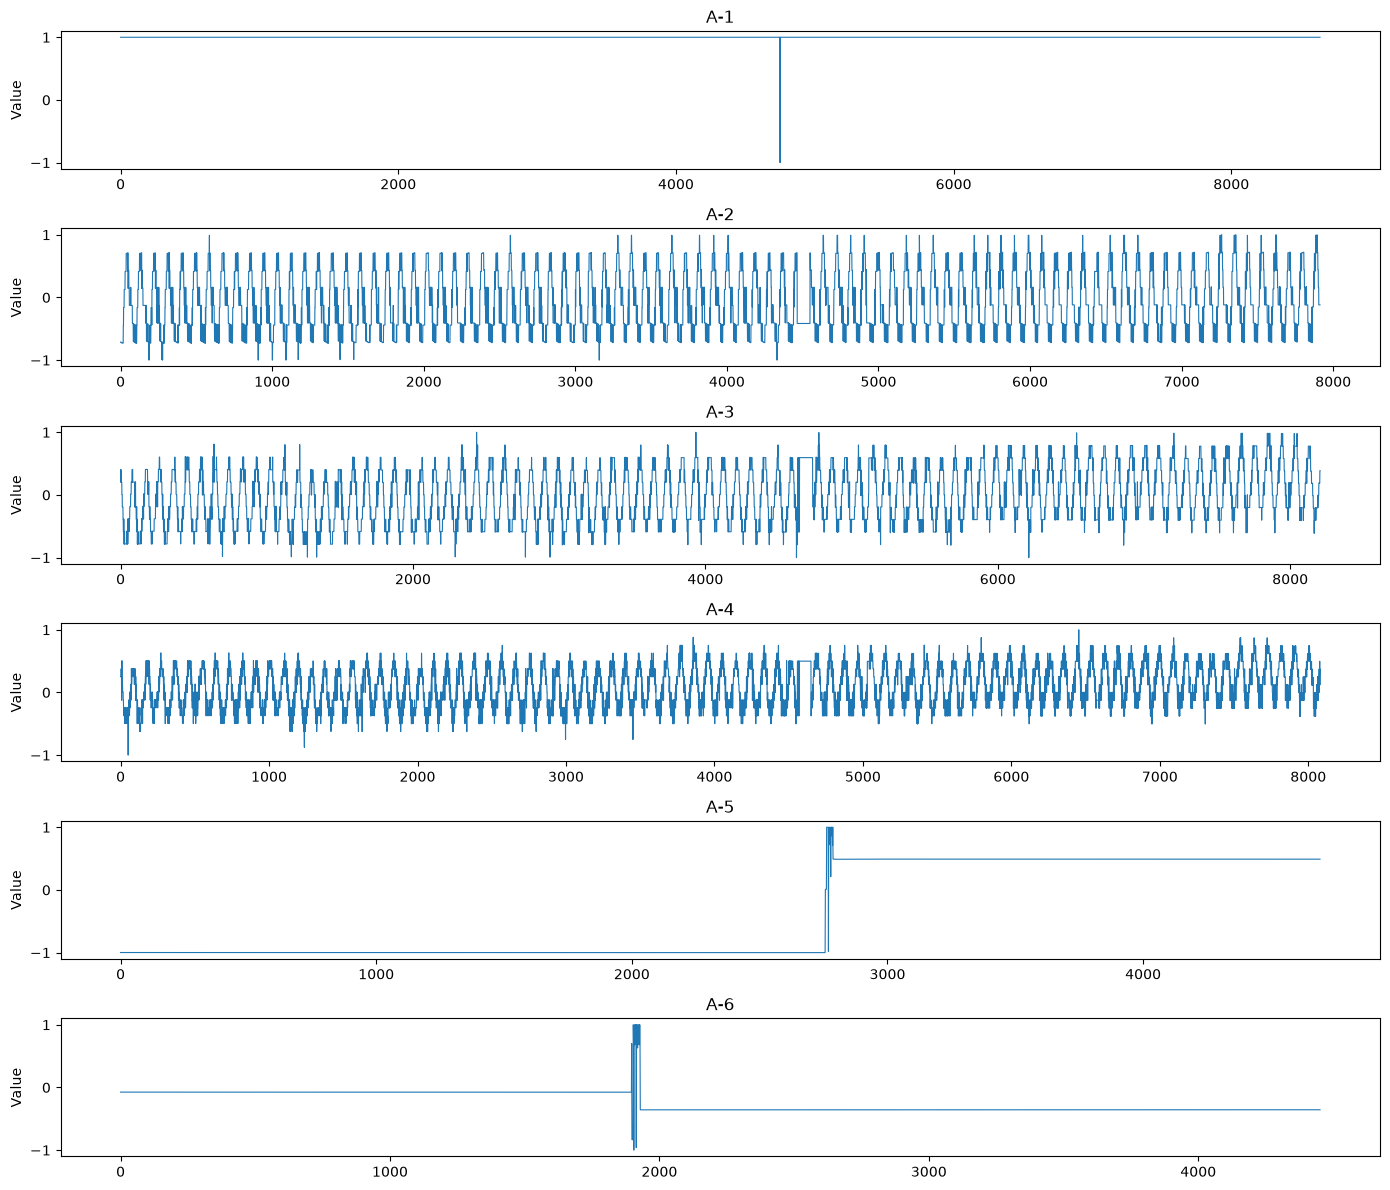

In [ ]:

test_dir = root / "data/raw/data/test"

# Compare the first 6 available channels
files = sorted(test_dir.glob("*.parquet"))[:6]

fig, axes = plt.subplots(
    len(files), 1,
    figsize=(14, 12)
)

for ax, file in zip(axes, files):
    df = pd.read_parquet(file)

    ax.plot(df["timestep"], df["value"], linewidth=0.8)
    ax.set_title(file.stem)
    ax.set_ylabel("Value")

plt.tight_layout()
plt.show()


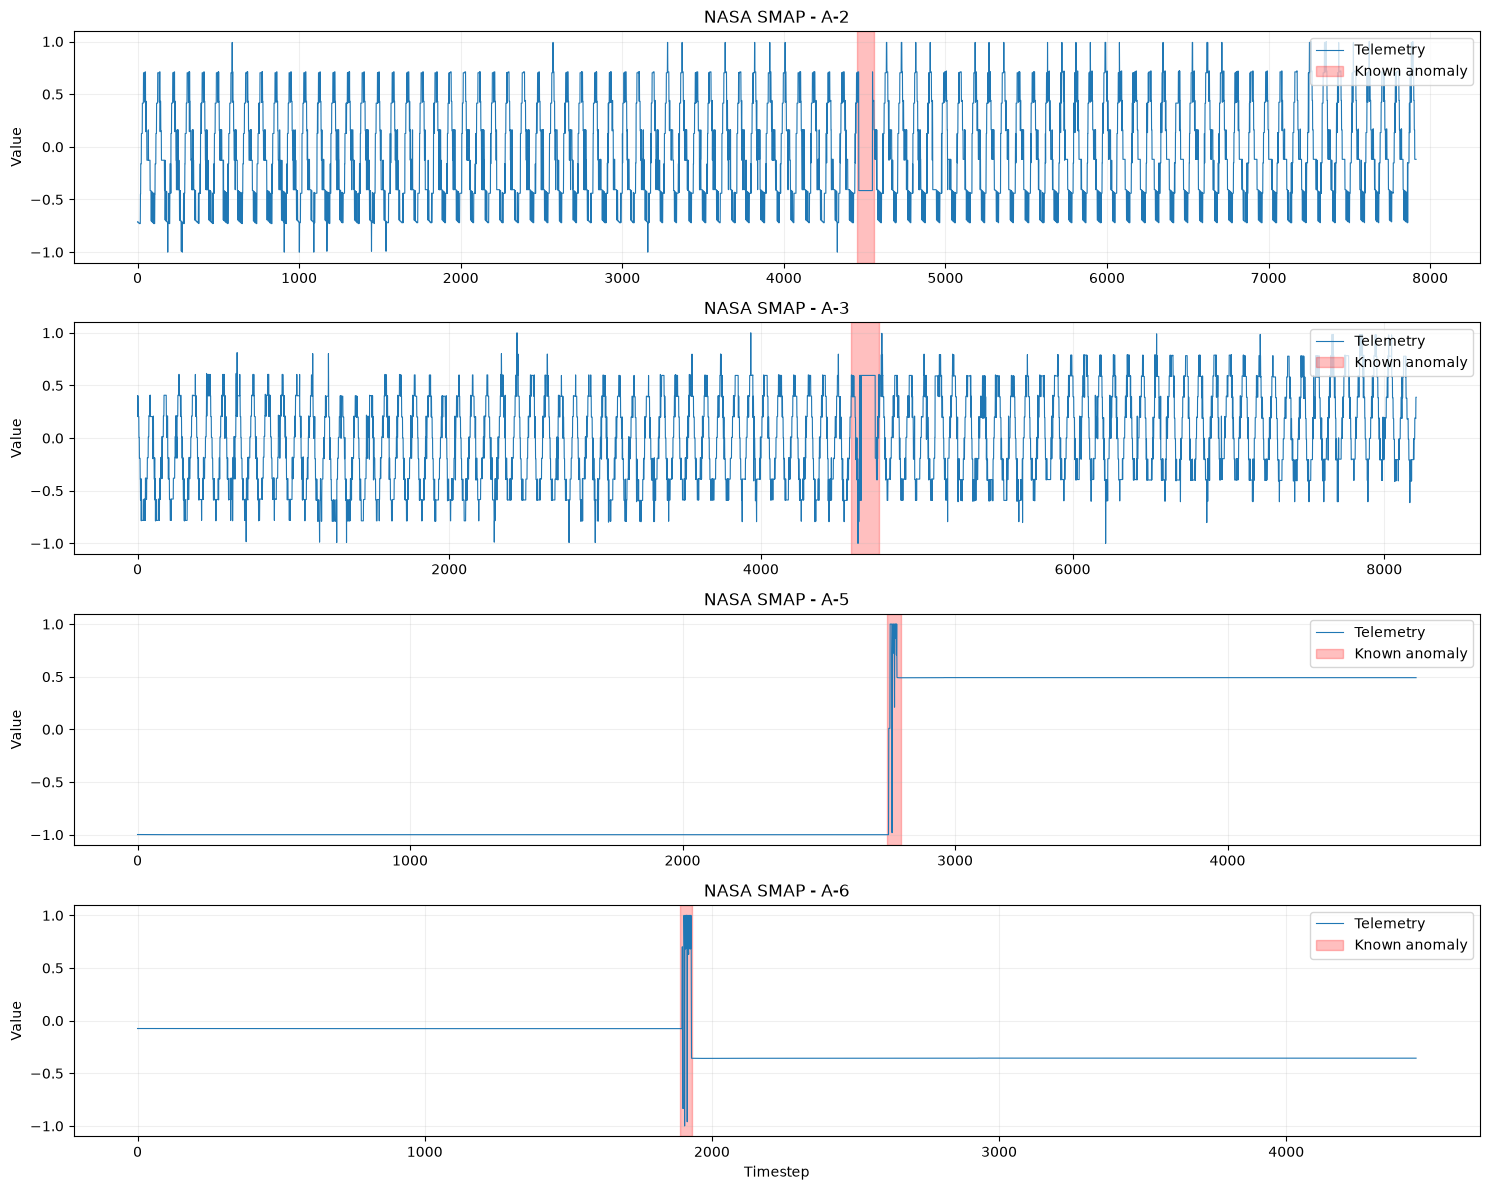

In [ ]:

channels = ["A-2", "A-3", "A-5", "A-6"]

fig, axes = plt.subplots(
    len(channels), 1,
    figsize=(15, 12)
)

for ax, channel in zip(axes, channels):
    df = pd.read_parquet(
        test_dir / f"{channel}.parquet"
    )

    # Find NASA's labeled anomaly intervals
    row = labels[labels["chan_id"] == channel]

    ax.plot(
        df["timestep"],
        df["value"],
        linewidth=0.8,
        label="Telemetry"
    )

    if not row.empty:
        intervals = ast.literal_eval(
            row.iloc[0]["anomaly_sequences"]
        )

        for i, (start, end) in enumerate(intervals):
            ax.axvspan(
                start, end,
                color="red",
                alpha=0.25,
                label="Known anomaly" if i == 0 else None
            )

    ax.set_title(f"NASA SMAP - {channel}")
    ax.set_ylabel("Value")
    ax.legend(loc="upper right")
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Timestep")
plt.tight_layout()
plt.show()


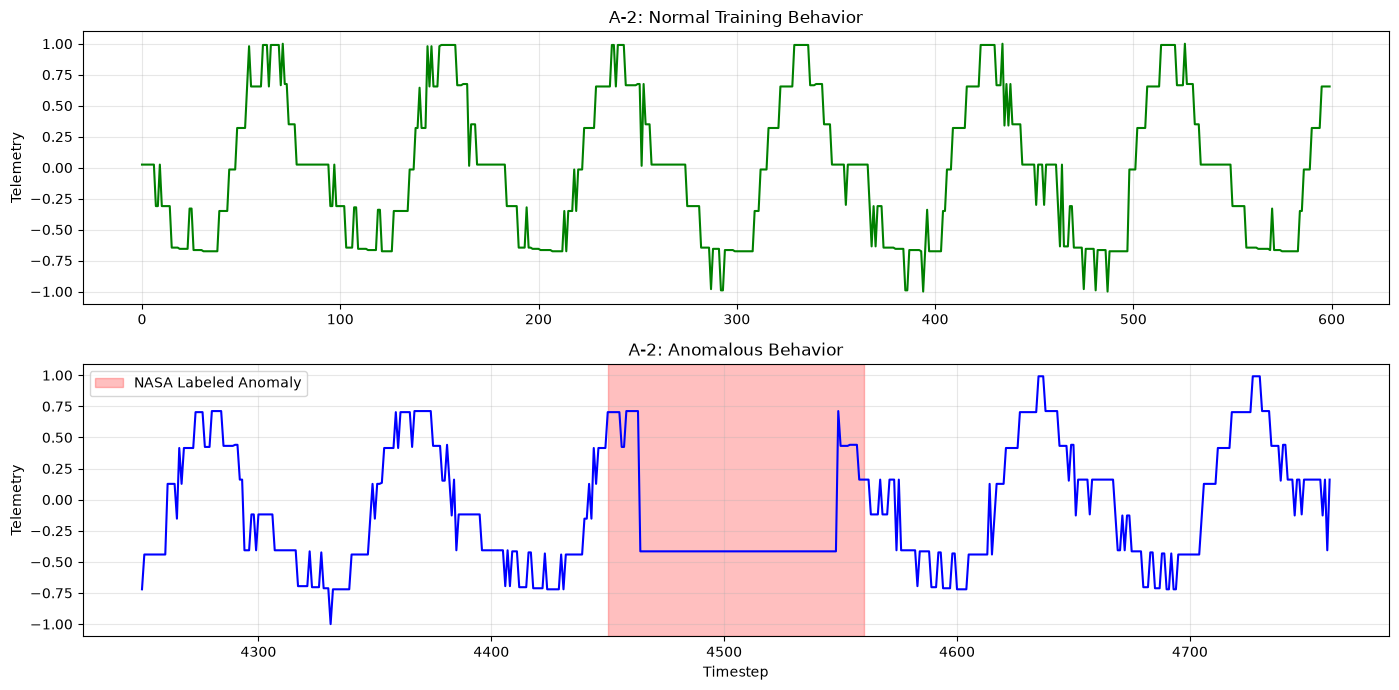

In [ ]:

channel = "A-2"

train_a2 = pd.read_parquet(
    root / f"data/raw/data/train/{channel}.parquet"
)

test_a2 = pd.read_parquet(
    root / f"data/raw/data/test/{channel}.parquet"
)

row = labels[labels["chan_id"] == channel]
intervals = ast.literal_eval(
    row.iloc[0]["anomaly_sequences"]
)

start, end = intervals[0]

fig, axes = plt.subplots(2, 1, figsize=(14, 7))

# Normal training sequence
train_sample = train_a2.iloc[:600]

axes[0].plot(
    train_sample["timestep"],
    train_sample["value"],
    color="green"
)
axes[0].set_title("A-2: Normal Training Behavior")
axes[0].set_ylabel("Telemetry")

# Test sequence around anomaly
anomaly_sample = test_a2[
    test_a2["timestep"].between(
        start - 200, end + 200
    )
]

axes[1].plot(
    anomaly_sample["timestep"],
    anomaly_sample["value"],
    color="blue"
)

axes[1].axvspan(
    start, end,
    color="red",
    alpha=0.25,
    label="NASA Labeled Anomaly"
)

axes[1].set_title("A-2: Anomalous Behavior")
axes[1].set_xlabel("Timestep")
axes[1].set_ylabel("Telemetry")
axes[1].legend()

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:

# Number of previous timesteps to examine
window = 30

# Reserve the last 20% of normal training data
# for selecting the detection threshold
split = int(len(train_a2) * 0.8)
validation = train_a2.iloc[split:]

# Calculate rolling standard deviation
val_std = validation["value"].rolling(
    window=window,
    min_periods=window
).std()

# Low variation is considered suspicious
# Calibrate using normal validation data only
threshold = val_std.dropna().quantile(0.01)

# Apply our detector to unseen test data
test_std = test_a2["value"].rolling(
    window=window,
    min_periods=window
).std()

# Flag periods with unusually low variation
predictions = (test_std < threshold).fillna(False)

print("Detection threshold:", threshold)
print("Flagged timesteps:", predictions.sum())


Detection threshold: 0.12346038923160181
Flagged timesteps: 75


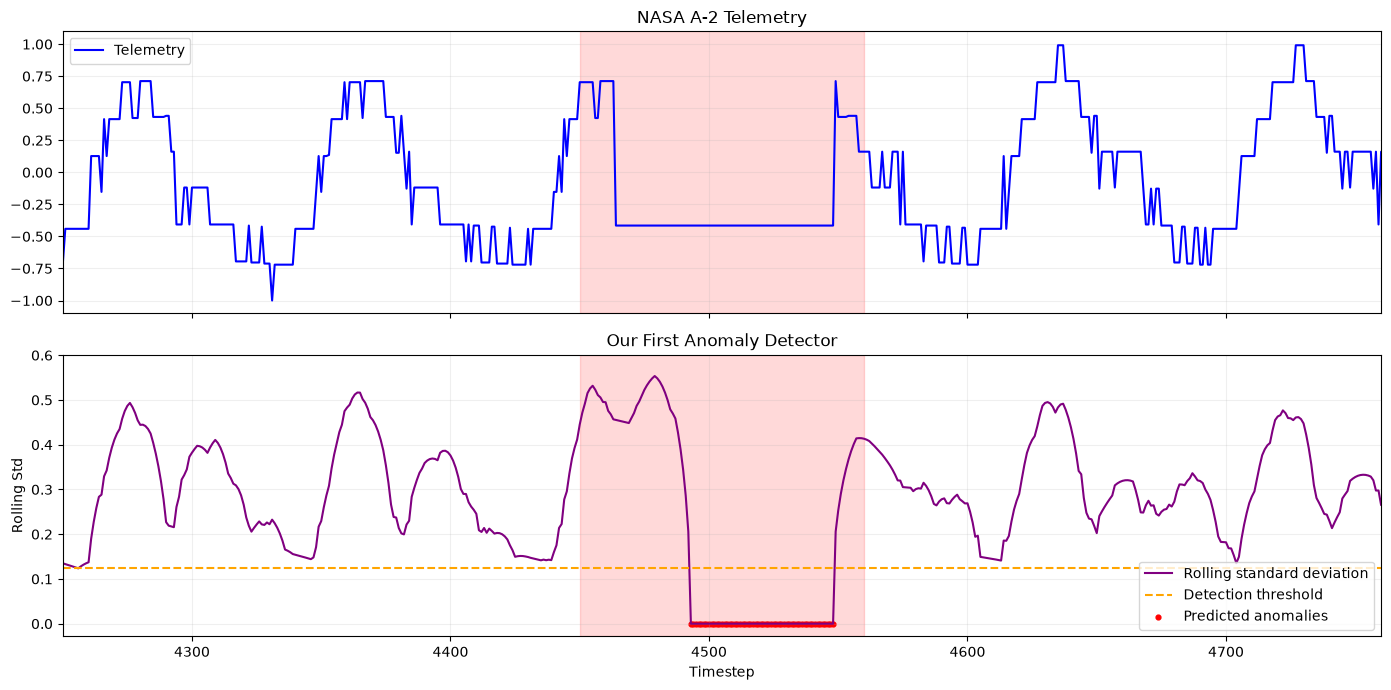

In [13]:

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

# Original telemetry
axes[0].plot(
    test_a2["timestep"],
    test_a2["value"],
    color="blue",
    label="Telemetry"
)

# Rolling standard deviation
axes[1].plot(
    test_a2["timestep"],
    test_std,
    color="purple",
    label="Rolling standard deviation"
)

axes[1].axhline(
    threshold,
    color="orange",
    linestyle="--",
    label="Detection threshold"
)

# Highlight predicted anomalous timesteps
axes[1].scatter(
    test_a2.loc[predictions, "timestep"],
    test_std.loc[predictions],
    color="red",
    s=12,
    label="Predicted anomalies"
)

# NASA labels for comparison
for ax in axes:
    for start, end in intervals:
        ax.axvspan(start, end, color="red", alpha=0.15)

    ax.grid(alpha=0.2)
    ax.legend()

# Zoom into the first labeled anomaly
start, end = intervals[0]

axes[1].set_xlim(start - 200, end + 200)

axes[0].set_title("NASA A-2 Telemetry")
axes[1].set_title("Our First Anomaly Detector")
axes[1].set_xlabel("Timestep")
axes[1].set_ylabel("Rolling Std")

plt.tight_layout()
plt.show()


In [14]:

# Create ground-truth labels from NASA's anomaly intervals
y_true = np.zeros(len(test_a2), dtype=bool)

for start, end in intervals:
    y_true |= test_a2["timestep"].between(
        start, end
    ).to_numpy()

# Our model's predictions
y_pred = predictions.to_numpy()

# Confusion matrix counts
tp = np.sum(y_true & y_pred)
fp = np.sum(~y_true & y_pred)
fn = np.sum(y_true & ~y_pred)
tn = np.sum(~y_true & ~y_pred)

# Evaluation metrics
precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"True Positives:  {tp}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"True Negatives:  {tn}")


Precision: 0.7467
Recall:    0.5045
F1 Score:  0.6022
True Positives:  56
False Positives: 19
False Negatives: 55
True Negatives:  7784


In [15]:

# Sliding window configuration
window_size = 100

# Use normal A-2 training telemetry
values = train_a2["value"].to_numpy(dtype="float32")

# Chronological 80/20 train-validation split
split = int(len(values) * 0.8)

train_values = values[:split]
val_values = values[split:]

# Create sequences for next-step prediction
X_train = np.array([
    train_values[i:i + window_size]
    for i in range(len(train_values) - window_size)
])

y_train = train_values[window_size:]

X_val = np.array([
    val_values[i:i + window_size]
    for i in range(len(val_values) - window_size)
])

y_val = val_values[window_size:]

# LSTM expects (samples, timesteps, features)
X_train = X_train.reshape(-1, window_size, 1)
X_val = X_val.reshape(-1, window_size, 1)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)


X_train: (2018, 100, 1)
y_train: (2018,)
X_val: (430, 100, 1)
y_val: (430,)


In [16]:

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)

# Use Apple Silicon GPU if available
device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

# Convert NumPy arrays to tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)

X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32)

# Create datasets
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

# Create batch loaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32)

print("Device:", device)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))


Device: mps
Training batches: 64
Validation batches: 14


In [17]:

class LSTMModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=32,
            batch_first=True
        )

        self.fc = nn.Linear(32, 1)

    def forward(self, x):
        output, _ = self.lstm(x)
        prediction = self.fc(output[:, -1, :])
        return prediction.squeeze(-1)


model = LSTMModel().to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print(model)


LSTMModel(
  (lstm): LSTM(1, 32, batch_first=True)
  (fc): Linear(in_features=32, out_features=1, bias=True)
)


In [18]:

epochs = 20

train_losses = []
val_losses = []

for epoch in range(epochs):
    model.train()
    train_loss = 0

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions_batch = model(X_batch)
        loss = criterion(predictions_batch, y_batch)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * len(X_batch)

    train_loss /= len(train_dataset)
    train_losses.append(train_loss)

    # Validation
    model.eval()
    val_loss = 0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions_batch = model(X_batch)
            loss = criterion(predictions_batch, y_batch)

            val_loss += loss.item() * len(X_batch)

    val_loss /= len(val_dataset)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Loss: {train_loss:.5f} | "
        f"Val Loss: {val_loss:.5f}"
    )


Epoch 1/20 | Train Loss: 0.18347 | Val Loss: 0.07793
Epoch 2/20 | Train Loss: 0.04349 | Val Loss: 0.04676
Epoch 3/20 | Train Loss: 0.03159 | Val Loss: 0.04053
Epoch 4/20 | Train Loss: 0.03092 | Val Loss: 0.03978
Epoch 5/20 | Train Loss: 0.03050 | Val Loss: 0.03828
Epoch 6/20 | Train Loss: 0.02828 | Val Loss: 0.03767
Epoch 7/20 | Train Loss: 0.02790 | Val Loss: 0.04571
Epoch 8/20 | Train Loss: 0.03048 | Val Loss: 0.03540
Epoch 9/20 | Train Loss: 0.02651 | Val Loss: 0.03429
Epoch 10/20 | Train Loss: 0.02558 | Val Loss: 0.03484
Epoch 11/20 | Train Loss: 0.02601 | Val Loss: 0.03354
Epoch 12/20 | Train Loss: 0.02577 | Val Loss: 0.03386
Epoch 13/20 | Train Loss: 0.02690 | Val Loss: 0.03253
Epoch 14/20 | Train Loss: 0.02534 | Val Loss: 0.03311
Epoch 15/20 | Train Loss: 0.02532 | Val Loss: 0.03191
Epoch 16/20 | Train Loss: 0.02588 | Val Loss: 0.03246
Epoch 17/20 | Train Loss: 0.02459 | Val Loss: 0.03178
Epoch 18/20 | Train Loss: 0.02427 | Val Loss: 0.03141
Epoch 19/20 | Train Loss: 0.02463 | V

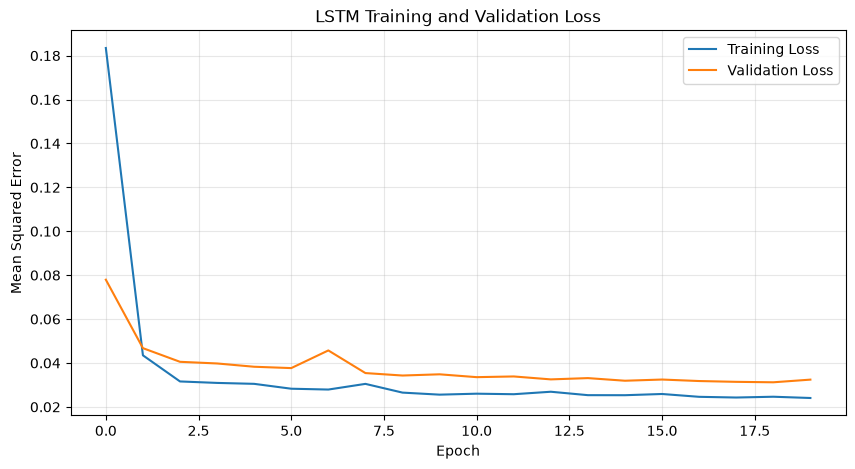

In [19]:

plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


In [20]:

# Predict normal validation telemetry
model.eval()

with torch.no_grad():
    val_preds = model(
        X_val_tensor.to(device)
    ).cpu().numpy()

# Calculate squared prediction errors
val_errors = (y_val - val_preds) ** 2

# Set threshold from normal validation data
lstm_threshold = np.quantile(val_errors, 0.99)

print(f"LSTM threshold: {lstm_threshold:.5f}")
print(f"Mean validation error: {val_errors.mean():.5f}")


LSTM threshold: 0.23872
Mean validation error: 0.03242


In [21]:

# Prepare unseen test telemetry
test_values = test_a2["value"].to_numpy(dtype="float32")

X_test = np.array([
    test_values[i:i + window_size]
    for i in range(len(test_values) - window_size)
]).reshape(-1, window_size, 1)

y_test = test_values[window_size:]

# Create batches for inference
test_dataset = TensorDataset(
    torch.tensor(X_test)
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128
)

# Predict test telemetry
test_preds = []

model.eval()

with torch.no_grad():
    for (X_batch,) in test_loader:
        output = model(X_batch.to(device))
        test_preds.extend(output.cpu().numpy())

test_preds = np.array(test_preds)

# Calculate anomaly scores
test_errors = (y_test - test_preds) ** 2

# Flag anomalies
lstm_predictions = test_errors > lstm_threshold

print("Test predictions:", len(test_preds))
print("Detected anomalous timesteps:", lstm_predictions.sum())


Test predictions: 7814
Detected anomalous timesteps: 39


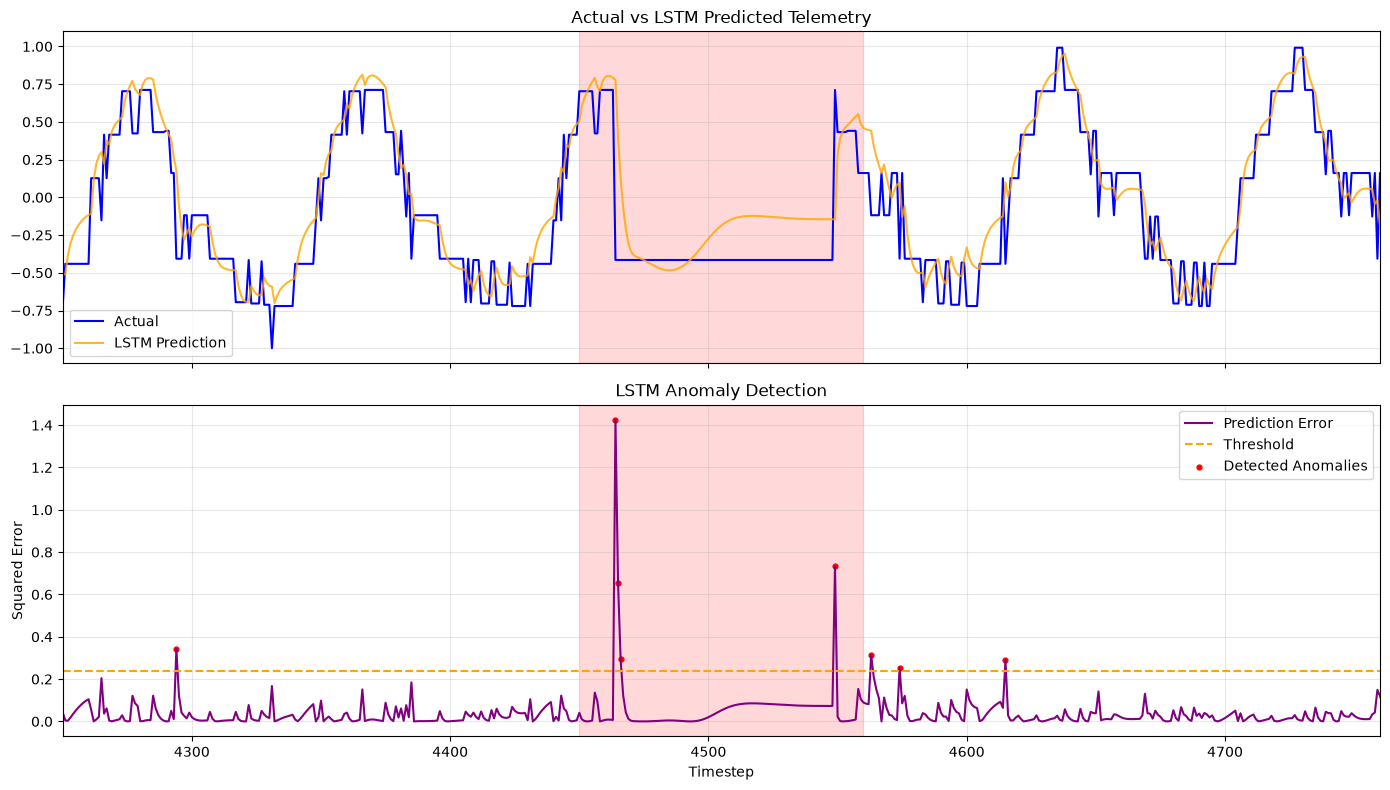

In [22]:

# Align predictions with original timestep values
test_timesteps = test_a2["timestep"].to_numpy()[window_size:]

fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 8),
    sharex=True
)

# Actual vs predicted telemetry
axes[0].plot(
    test_timesteps, y_test,
    label="Actual",
    color="blue"
)

axes[0].plot(
    test_timesteps, test_preds,
    label="LSTM Prediction",
    color="orange",
    alpha=0.8
)

# Anomaly scores
axes[1].plot(
    test_timesteps, test_errors,
    label="Prediction Error",
    color="purple"
)

axes[1].axhline(
    lstm_threshold,
    color="orange",
    linestyle="--",
    label="Threshold"
)

axes[1].scatter(
    test_timesteps[lstm_predictions],
    test_errors[lstm_predictions],
    color="red",
    s=12,
    label="Detected Anomalies"
)

# NASA ground-truth intervals
for ax in axes:
    for start, end in intervals:
        ax.axvspan(
            start, end,
            color="red",
            alpha=0.15
        )

    ax.legend()
    ax.grid(alpha=0.3)

# Zoom into the first known anomaly
start, end = intervals[0]
axes[1].set_xlim(start - 200, end + 200)

axes[0].set_title("Actual vs LSTM Predicted Telemetry")
axes[1].set_title("LSTM Anomaly Detection")
axes[1].set_xlabel("Timestep")
axes[1].set_ylabel("Squared Error")

plt.tight_layout()
plt.show()


In [23]:

# Align ground truth with LSTM predictions
lstm_true = y_true[window_size:]

tp_lstm = np.sum(lstm_true & lstm_predictions)
fp_lstm = np.sum(~lstm_true & lstm_predictions)
fn_lstm = np.sum(lstm_true & ~lstm_predictions)

precision_lstm = tp_lstm / (tp_lstm + fp_lstm) if tp_lstm + fp_lstm else 0
recall_lstm = tp_lstm / (tp_lstm + fn_lstm) if tp_lstm + fn_lstm else 0
f1_lstm = 2 * precision_lstm * recall_lstm / (precision_lstm + recall_lstm) if precision_lstm + recall_lstm else 0

print("LSTM Results:")
print(f"Precision: {precision_lstm:.4f}")
print(f"Recall:    {recall_lstm:.4f}")
print(f"F1 Score:  {f1_lstm:.4f}")

# Recalculate baseline on the same evaluated timesteps
baseline_pred = y_pred[window_size:]

bp = np.sum(lstm_true & baseline_pred)
bfp = np.sum(~lstm_true & baseline_pred)
bfn = np.sum(lstm_true & ~baseline_pred)

baseline_precision = bp / (bp + bfp) if bp + bfp else 0
baseline_recall = bp / (bp + bfn) if bp + bfn else 0
baseline_f1 = (
    2 * baseline_precision * baseline_recall
    / (baseline_precision + baseline_recall)
    if baseline_precision + baseline_recall else 0
)

print(f"\nBaseline F1 (same timesteps): {baseline_f1:.4f}")
print(f"LSTM F1:                       {f1_lstm:.4f}")


LSTM Results:
Precision: 0.1026
Recall:    0.0360
F1 Score:  0.0533

Baseline F1 (same timesteps): 0.6022
LSTM F1:                       0.0533


In [24]:

# Combine baseline and LSTM predictions
hybrid_predictions = baseline_pred | lstm_predictions

# Calculate evaluation metrics
hybrid_tp = np.sum(lstm_true & hybrid_predictions)
hybrid_fp = np.sum(~lstm_true & hybrid_predictions)
hybrid_fn = np.sum(lstm_true & ~hybrid_predictions)

hybrid_precision = (
    hybrid_tp / (hybrid_tp + hybrid_fp)
    if hybrid_tp + hybrid_fp else 0
)

hybrid_recall = (
    hybrid_tp / (hybrid_tp + hybrid_fn)
    if hybrid_tp + hybrid_fn else 0
)

hybrid_f1 = (
    2 * hybrid_precision * hybrid_recall
    / (hybrid_precision + hybrid_recall)
    if hybrid_precision + hybrid_recall else 0
)

# Compare all three approaches
results = pd.DataFrame({
    "Model": [
        "Statistical Baseline",
        "LSTM",
        "Hybrid"
    ],
    "Precision": [
        baseline_precision,
        precision_lstm,
        hybrid_precision
    ],
    "Recall": [
        baseline_recall,
        recall_lstm,
        hybrid_recall
    ],
    "F1 Score": [
        baseline_f1,
        f1_lstm,
        hybrid_f1
    ]
})

display(results.round(4))


,Model,Precision,Recall,F1 Score
0,Statistical Baseline,0.7467,0.5045,0.6022
1,LSTM,0.1026,0.0360,0.0533
2,Hybrid,0.5263,0.5405,0.5333


In [25]:

# Predict the next 30 readings
horizon = 30

# Training windows
X_train_multi = np.array([
    train_values[i:i + window_size]
    for i in range(len(train_values) - window_size - horizon + 1)
], dtype="float32").reshape(-1, window_size, 1)

y_train_multi = np.array([
    train_values[i + window_size:i + window_size + horizon]
    for i in range(len(train_values) - window_size - horizon + 1)
], dtype="float32")

# Validation windows
X_val_multi = np.array([
    val_values[i:i + window_size]
    for i in range(len(val_values) - window_size - horizon + 1)
], dtype="float32").reshape(-1, window_size, 1)

y_val_multi = np.array([
    val_values[i + window_size:i + window_size + horizon]
    for i in range(len(val_values) - window_size - horizon + 1)
], dtype="float32")

print("X_train:", X_train_multi.shape)
print("y_train:", y_train_multi.shape)
print("X_val:", X_val_multi.shape)
print("y_val:", y_val_multi.shape)


X_train: (1989, 100, 1)
y_train: (1989, 30)
X_val: (401, 100, 1)
y_val: (401, 30)


In [26]:

class MultiStepLSTM(nn.Module):
    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=32,
            batch_first=True
        )

        self.fc = nn.Linear(32, horizon)

    def forward(self, x):
        output, _ = self.lstm(x)
        return self.fc(output[:, -1, :])


# Prepare DataLoaders
train_loader_multi = DataLoader(
    TensorDataset(
        torch.from_numpy(X_train_multi),
        torch.from_numpy(y_train_multi)
    ),
    batch_size=32,
    shuffle=True
)

val_loader_multi = DataLoader(
    TensorDataset(
        torch.from_numpy(X_val_multi),
        torch.from_numpy(y_val_multi)
    ),
    batch_size=32
)

model_multi = MultiStepLSTM().to(device)

optimizer_multi = torch.optim.Adam(
    model_multi.parameters(),
    lr=0.001
)

print(model_multi)



MultiStepLSTM(
  (lstm): LSTM(1, 32, batch_first=True)
  (fc): Linear(in_features=32, out_features=30, bias=True)
)


In [27]:

multi_train_losses = []
multi_val_losses = []

best_val = float("inf")
best_state = None

for epoch in range(15):
    model_multi.train()
    train_loss = 0

    for X_batch, y_batch in train_loader_multi:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer_multi.zero_grad()

        output = model_multi(X_batch)
        loss = criterion(output, y_batch)

        loss.backward()
        optimizer_multi.step()

        train_loss += loss.item() * len(X_batch)

    train_loss /= len(X_train_multi)

    model_multi.eval()
    val_loss = 0

    with torch.no_grad():
        for X_batch, y_batch in val_loader_multi:
            output = model_multi(X_batch.to(device))
            loss = criterion(output, y_batch.to(device))
            val_loss += loss.item() * len(X_batch)

    val_loss /= len(X_val_multi)

    multi_train_losses.append(train_loss)
    multi_val_losses.append(val_loss)

    if val_loss < best_val:
        best_val = val_loss
        best_state = {
            k: v.detach().cpu().clone()
            for k, v in model_multi.state_dict().items()
        }

    print(
        f"Epoch {epoch+1:02d} | "
        f"Train: {train_loss:.5f} | "
        f"Val: {val_loss:.5f}"
    )

# Restore best-performing model
model_multi.load_state_dict(best_state)

print(f"\nBest validation loss: {best_val:.5f}")


Epoch 01 | Train: 0.30176 | Val: 0.27415
Epoch 02 | Train: 0.14614 | Val: 0.06909
Epoch 03 | Train: 0.04970 | Val: 0.05093
Epoch 04 | Train: 0.04308 | Val: 0.04674
Epoch 05 | Train: 0.04060 | Val: 0.04395
Epoch 06 | Train: 0.03982 | Val: 0.04642
Epoch 07 | Train: 0.03832 | Val: 0.04377
Epoch 08 | Train: 0.03680 | Val: 0.04124
Epoch 09 | Train: 0.03604 | Val: 0.04080
Epoch 10 | Train: 0.03613 | Val: 0.03995
Epoch 11 | Train: 0.03497 | Val: 0.04045
Epoch 12 | Train: 0.03533 | Val: 0.04135
Epoch 13 | Train: 0.03472 | Val: 0.03830
Epoch 14 | Train: 0.03372 | Val: 0.03869
Epoch 15 | Train: 0.03373 | Val: 0.03814

Best validation loss: 0.03814


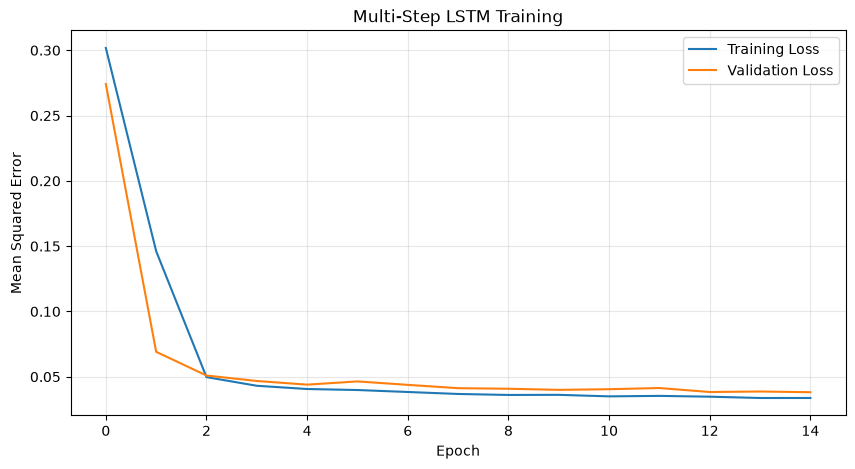

In [28]:

plt.figure(figsize=(10, 5))

plt.plot(multi_train_losses, label="Training Loss")
plt.plot(multi_val_losses, label="Validation Loss")

plt.title("Multi-Step LSTM Training")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [29]:

# Generate validation forecasts
model_multi.eval()

with torch.no_grad():
    val_forecasts = np.concatenate([
        model_multi(X_batch.to(device)).cpu().numpy()
        for X_batch, _ in val_loader_multi
    ])

# Average prediction error across 30 timesteps
val_scores = np.mean(
    (y_val_multi - val_forecasts) ** 2,
    axis=1
)

# Calibrate threshold using normal validation data
multi_threshold = np.quantile(val_scores, 0.99)

print(f"Multi-step threshold: {multi_threshold:.5f}")

# Prepare test sequences
X_test_multi = np.array([
    test_values[i:i + window_size]
    for i in range(len(test_values) - window_size - horizon + 1)
], dtype="float32").reshape(-1, window_size, 1)

y_test_multi = np.array([
    test_values[i + window_size:i + window_size + horizon]
    for i in range(len(test_values) - window_size - horizon + 1)
], dtype="float32")

# Generate test forecasts in batches
test_forecasts = []

with torch.no_grad():
    for i in range(0, len(X_test_multi), 128):
        batch = torch.from_numpy(
            X_test_multi[i:i + 128]
        ).to(device)

        test_forecasts.append(
            model_multi(batch).cpu().numpy()
        )

test_forecasts = np.concatenate(test_forecasts)

# Calculate test anomaly scores
multi_scores = np.mean(
    (y_test_multi - test_forecasts) ** 2,
    axis=1
)

multi_predictions = multi_scores > multi_threshold

print("Test windows:", len(multi_scores))
print("Flagged timesteps:", multi_predictions.sum())


Multi-step threshold: 0.06916
Test windows: 7785
Flagged timesteps: 1620


In [30]:

# Align labels with the END of each forecast
offset = window_size + horizon - 1

multi_true = y_true[offset:]
multi_baseline = y_pred[offset:]

assert len(multi_true) == len(multi_predictions)

comparison = []

for name, pred in [
    ("Statistical Baseline", multi_baseline),
    ("30-Step LSTM", multi_predictions)
]:
    tp = np.sum(multi_true & pred)
    fp = np.sum(~multi_true & pred)
    fn = np.sum(multi_true & ~pred)

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    comparison.append({
        "Model": name,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "TP": tp,
        "FP": fp,
        "FN": fn
    })

display(pd.DataFrame(comparison).round(4))


,Model,Precision,Recall,F1 Score,TP,FP,FN
0,Statistical Baseline,0.7467,0.5045,0.6022,56,19,55
1,30-Step LSTM,0.0401,0.5856,0.0751,65,1555,46


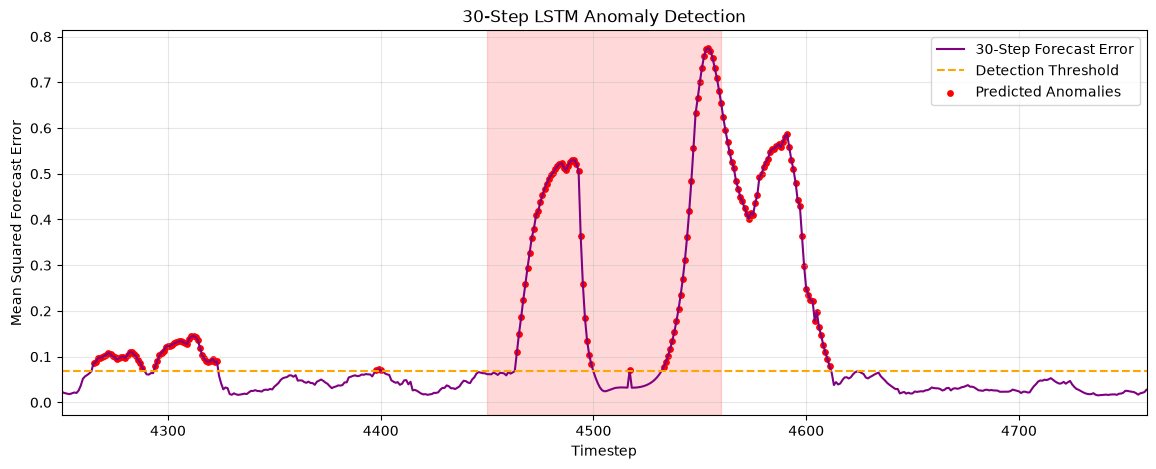

In [31]:

# Match scores to the correct test timesteps
multi_timesteps = test_a2["timestep"].to_numpy()[offset:]

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    multi_timesteps,
    multi_scores,
    color="purple",
    label="30-Step Forecast Error"
)

ax.axhline(
    multi_threshold,
    color="orange",
    linestyle="--",
    label="Detection Threshold"
)

ax.scatter(
    multi_timesteps[multi_predictions],
    multi_scores[multi_predictions],
    color="red",
    s=15,
    label="Predicted Anomalies"
)

# Show NASA's labeled anomaly intervals
for start, end in intervals:
    ax.axvspan(
        start, end,
        color="red",
        alpha=0.15
    )

# Zoom into A-2's first known anomaly
start, end = intervals[0]
ax.set_xlim(start - 200, end + 200)

ax.set_title("30-Step LSTM Anomaly Detection")
ax.set_xlabel("Timestep")
ax.set_ylabel("Mean Squared Forecast Error")
ax.legend()
ax.grid(alpha=0.3)

plt.show()


In [32]:

# Compare prediction error distributions
score_groups = {
    "Normal Validation": val_scores,
    "Test Outside Anomalies": multi_scores[~multi_true],
    "Test Labeled Anomalies": multi_scores[multi_true]
}

diagnostics = []

for name, scores in score_groups.items():
    diagnostics.append({
        "Group": name,
        "Count": len(scores),
        "Median Error": np.median(scores),
        "95th Percentile": np.quantile(scores, 0.95),
        "Flagged %": 100 * np.mean(scores > multi_threshold)
    })

display(pd.DataFrame(diagnostics).round(4))


,Group,Count,Median Error,95th Percentile,Flagged %
0,Normal Validation,401,0.0337,0.0651,0.9975
1,Test Outside Anomalies,7674,0.0342,0.1311,20.2632
2,Test Labeled Anomalies,111,0.1348,0.7315,58.5586


In [33]:

# Align all models to the same evaluated timesteps
model_predictions = {
    "Rolling Std": y_pred[offset:],
    "Single-Step LSTM": lstm_predictions[offset - window_size:],
    "Hybrid": hybrid_predictions[offset - window_size:],
    "30-Step LSTM": multi_predictions
}

records = []

for name, pred in model_predictions.items():
    tp = np.sum(multi_true & pred)
    fp = np.sum(~multi_true & pred)
    fn = np.sum(multi_true & ~pred)

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0

    records.append({
        "Model": name,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "TP": tp,
        "FP": fp,
        "FN": fn
    })

report = pd.DataFrame(records)

# Save experiment results
(root / "reports").mkdir(exist_ok=True)

report.to_csv(
    root / "reports/a2_exploratory_comparison.csv",
    index=False
)

display(report.round(4))


,Model,Precision,Recall,F1,TP,FP,FN
0,Rolling Std,0.7467,0.5045,0.6022,56,19,55
1,Single-Step LSTM,0.1026,0.0360,0.0533,4,35,107
2,Hybrid,0.5263,0.5405,0.5333,60,54,51
3,30-Step LSTM,0.0401,0.5856,0.0751,65,1555,46


In [34]:

channels = ["A-2", "A-7", "P-1", "M-1"]

reports = []

for channel in channels:
    path = root / f"reports/{channel}_h1_evaluation.csv"

    df = pd.read_csv(path)
    df.insert(0, "Channel", channel)

    reports.append(df)

summary = pd.concat(reports, ignore_index=True)

display(
    summary[
        ["Channel", "Model", "Precision", "Recall", "F1", "TP", "FP", "FN"]
    ].round(4)
)

summary.to_csv(
    root / "reports/channel_comparison_h1.csv",
    index=False
)


,Channel,Model,Precision,Recall,F1,TP,FP,FN
0,A-2,Rolling Std,0.7467,0.5045,0.6022,56,19,55
1,A-2,LSTM h=1,0.1875,0.0270,0.0472,3,13,108
2,A-7,Rolling Std,0.9653,0.9725,0.9689,2335,84,66
3,A-7,LSTM h=1,0.0122,0.0017,0.0029,4,323,2397
4,P-1,Rolling Std,0.9223,0.2530,0.3971,190,16,561
5,P-1,LSTM h=1,0.0843,0.0186,0.0305,14,152,737
6,M-1,Rolling Std,0.8841,0.0535,0.1008,61,8,1080
7,M-1,LSTM h=1,0.0526,0.0009,0.0017,1,18,1140


In [35]:

channels = ["A-2", "A-7", "P-1", "M-1"]

feature_report = []

for channel in channels:
    df = pd.read_parquet(
        root / f"data/raw/data/train/{channel}.parquet"
    )

    command_cols = [
        col for col in df.columns
        if col.startswith("cmd_")
    ]

    commands = df[command_cols]

    changes = commands.ne(
        commands.shift()
    ).any(axis=1).iloc[1:].sum()

    feature_report.append({
        "Channel": channel,
        "Timesteps": len(df),
        "Command Features": len(command_cols),
        "Unique Command States": len(commands.drop_duplicates()),
        "Command Changes": int(changes),
        "Missing Values": int(df.isna().sum().sum())
    })

display(pd.DataFrame(feature_report))


,Channel,Timesteps,Command Features,Unique Command States,Command Changes,Missing Values
0,A-2,2648,24,29,479,0
1,A-7,2879,24,9,21,0
2,P-1,2872,24,28,504,0
3,M-1,2209,54,13,874,0
